# FarmWatch AI: MobileNetV3-Small Transfer-Learning Benchmark

**Hackathon Problem Statement:** GenHack V1.0 — PS 12: Predicting Crop Stress From Field Images  
**Experiment:** Controlled MobileNetV3-Small Transfer Learning vs. Scratch-Trained Custom CNN  
**Hardware Platform:** ASUS Zenbook 14 OLED | Intel Core Ultra 5 125H (14 Cores) | 16 GB RAM | Windows 11  

---

## 1. Executive Summary & Experiment Framing

In the initial phase of FarmWatch AI, we designed and trained two custom convolutional networks from random initialization (Kaiming Normal):
1. **Baseline Custom CNN (28 classes):** Scratch-trained on the full PlantDoc benchmark (Test Accuracy: 18.29%, Macro F1: 11.17%). Audit revealed severe class imbalance (down to 2 images/class) and 13 zero-F1 classes.
2. **Enhanced Crop CNN (11 classes):** Scratch-trained on 11 well-represented classes ($\ge 100$ images each) with class-weighted loss, label smoothing, and cosine annealing (Test Accuracy: 27.10%, Macro F1: 21.74%).

### Transfer-Learning Hypothesis:
While scratch training guarantees zero external data bias, agricultural leaf pathology classification on small field datasets ($\sim 1,000$ training images) often benefits substantially from generic low-level feature representations (edges, textures, color gradients) learned on large-scale visual corpora like ImageNet-1K.

### Non-Negotiable Integrity Boundaries:
1. **Explicit Labeling:** MobileNetV3-Small is explicitly labeled as **transfer learning / fine-tuning with ImageNet pretrained weights**. It is never claimed as trained from scratch.
2. **Identical Partitions & Zero Leakage:** Evaluated on the exact same 11-class manifests (Train: 951, Val: 200, Test: 214) with 0 content hash overlap.
3. **No Test Set Tuning:** Checkpoints are selected solely via **Validation Macro F1**; the test set is evaluated exactly once.
4. **Honest Metric Reporting:** All numbers are computed directly from executed scripts on actual hardware.


## 2. Hardware Environment & Compute Abstraction
We probe the runtime environment on the ASUS Zenbook 14 OLED. The system queries PyTorch's backend for Intel Arc XPU acceleration and falls back gracefully to the 14-core Intel Core Ultra 5 125H CPU.


In [1]:
import sys
import os
import json
from pathlib import Path
import torch

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.device import get_torch_device, get_device_info

device = get_torch_device()
info = get_device_info()

print(f"Active Device: {device}")
print(f"Device Name: {info.get('device_name')}")
print(f"PyTorch Version: {torch.__version__}")
print(f"XPU Available: {info.get('xpu_is_available')}")


Active Device: cpu
Device Name: CPU (Intel Core Ultra 5 125H)
PyTorch Version: 2.14.1+cpu
XPU Available: False


## 3. Dataset Audit & Partition Integrity
We verify the focused 11-class subset derived from PlantDoc. We confirm sample counts, class distributions, and verify zero data leakage across train, validation, and test splits.


In [2]:
manifest_dir = PROJECT_ROOT / "data" / "manifests"
train_path = manifest_dir / "focused_train_manifest.json"
val_path = manifest_dir / "focused_val_manifest.json"
test_path = manifest_dir / "focused_test_manifest.json"

with open(train_path, "r", encoding="utf-8") as f:
    train_manifest = json.load(f)
with open(val_path, "r", encoding="utf-8") as f:
    val_manifest = json.load(f)
with open(test_path, "r", encoding="utf-8") as f:
    test_manifest = json.load(f)

print(f"Train samples: {len(train_manifest)}")
print(f"Val samples:   {len(val_manifest)}")
print(f"Test samples:  {len(test_manifest)}")

# Verify hash disjointness (Zero Data Leakage)
train_hashes = {x["sha256"] for x in train_manifest}
val_hashes = {x["sha256"] for x in val_manifest}
test_hashes = {x["sha256"] for x in test_manifest}

overlap_tv = train_hashes & val_hashes
overlap_tt = train_hashes & test_hashes
overlap_vt = val_hashes & test_hashes

print(f"Train/Val hash collisions:  {len(overlap_tv)}")
print(f"Train/Test hash collisions: {len(overlap_tt)}")
print(f"Val/Test hash collisions:   {len(overlap_vt)}")
assert len(overlap_tv) == 0 and len(overlap_tt) == 0 and len(overlap_vt) == 0, "Data leakage detected!"
print(">>> Zero Data Leakage verified across all partitions.")


Train samples: 951
Val samples:   200
Test samples:  214
Train/Val hash collisions:  0
Train/Test hash collisions: 0
Val/Test hash collisions:   0
>>> Zero Data Leakage verified across all partitions.


## 4. MobileNetV3-Small Architecture & Two-Stage Training Strategy

MobileNetV3-Small was selected for its high parameter efficiency (~1.5M parameters) and suitability for mobile/edge deployment.

### Transfer-Learning Strategy:
1. **Backbone:** Torchvision's `mobilenet_v3_small` with default ImageNet-1K pretrained weights (`MobileNet_V3_Small_Weights.DEFAULT`).
2. **Classifier Head Adaptation:** The original 1000-class linear projection is replaced with a custom projection layer:
   $$\text{Linear}(1024 \to 11)$$
3. **Stage 1 (Head Warm-up, Epochs 1-4):**
   - All backbone feature blocks (`model.features`) are frozen (`requires_grad = False`).
   - Only classifier head parameters (602,123 parameters) are trained with AdamW ($lr = 10^{-3}$, weight decay $= 10^{-4}$).
4. **Stage 2 (Fine-Tuning, Epochs 5-12):**
   - The top feature blocks (`model.features[9:]`) are unfrozen.
   - Differential learning rates: $lr = 10^{-4}$ for top backbone layers, $lr = 5 \times 10^{-4}$ for the classification head.
   - Cosine annealing learning rate scheduler.


In [3]:
import torchvision.models as models
from torchvision.models import MobileNet_V3_Small_Weights
import torch.nn as nn

# Inspect architecture
model = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
model.classifier[3] = nn.Linear(1024, 11)

total_params = sum(p.numel() for p in model.parameters())
trainable_params_all = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
print(f"Classifier Structure:\n{model.classifier}")


Total Parameters: 1,529,131
Classifier Structure:
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=11, bias=True)
)


## 5. Training History & Learning Curves
We load the actual logged training progression from `reports/mobilenetv3_training_history.csv` and visualize loss, accuracy, and validation macro F1.


In [4]:
import csv

history_csv = PROJECT_ROOT / "reports" / "mobilenetv3_training_history.csv"
if history_csv.exists():
    with open(history_csv, "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        rows = list(reader)
    header = rows[0]
    print(f"{'Ep':>3} | {'Stage':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7} | {'Val F1':>7} | {'LR':>9} | {'Best?':>5}")
    print("-" * 80)
    for r in rows[1:]:
        print(f"{r[0]:>3} | {r[1]:>5} | {float(r[2]):>10.4f} | {float(r[3])*100:>8.2f}% | {float(r[4]):>8.4f} | {float(r[5])*100:>6.2f}% | {float(r[6])*100:>6.2f}% | {float(r[7]):>9.6f} | {r[9]:>5}")
else:
    print(f"History file not found at {history_csv}")


 Ep | Stage | Train Loss | Train Acc | Val Loss | Val Acc |  Val F1 |        LR | Best?
--------------------------------------------------------------------------------
  1 |     1 |     1.7927 |    43.64% |   1.3029 |  59.00% |  58.33% |  0.001000 |  True
  2 |     1 |     1.2946 |    62.15% |   1.2307 |  62.00% |  59.67% |  0.000855 |  True
  3 |     1 |     1.1440 |    68.24% |   1.1797 |  65.50% |  64.17% |  0.000505 |  True
  4 |     1 |     1.0520 |    73.61% |   1.1451 |  65.50% |  64.47% |  0.000155 |  True
  5 |     2 |     1.0949 |    69.82% |   1.1627 |  64.00% |  62.77% |  0.000100 | False
  6 |     2 |     0.9655 |    76.66% |   1.0871 |  67.50% |  66.15% |  0.000096 |  True
  7 |     2 |     0.8837 |    77.92% |   1.0745 |  66.00% |  64.85% |  0.000086 | False
  8 |     2 |     0.8363 |    81.91% |   1.1262 |  66.00% |  64.66% |  0.000069 | False
  9 |     2 |     0.7733 |    83.49% |   1.0877 |  66.50% |  65.14% |  0.000051 | False
 10 |     2 |     0.7344 |    86.65% | 

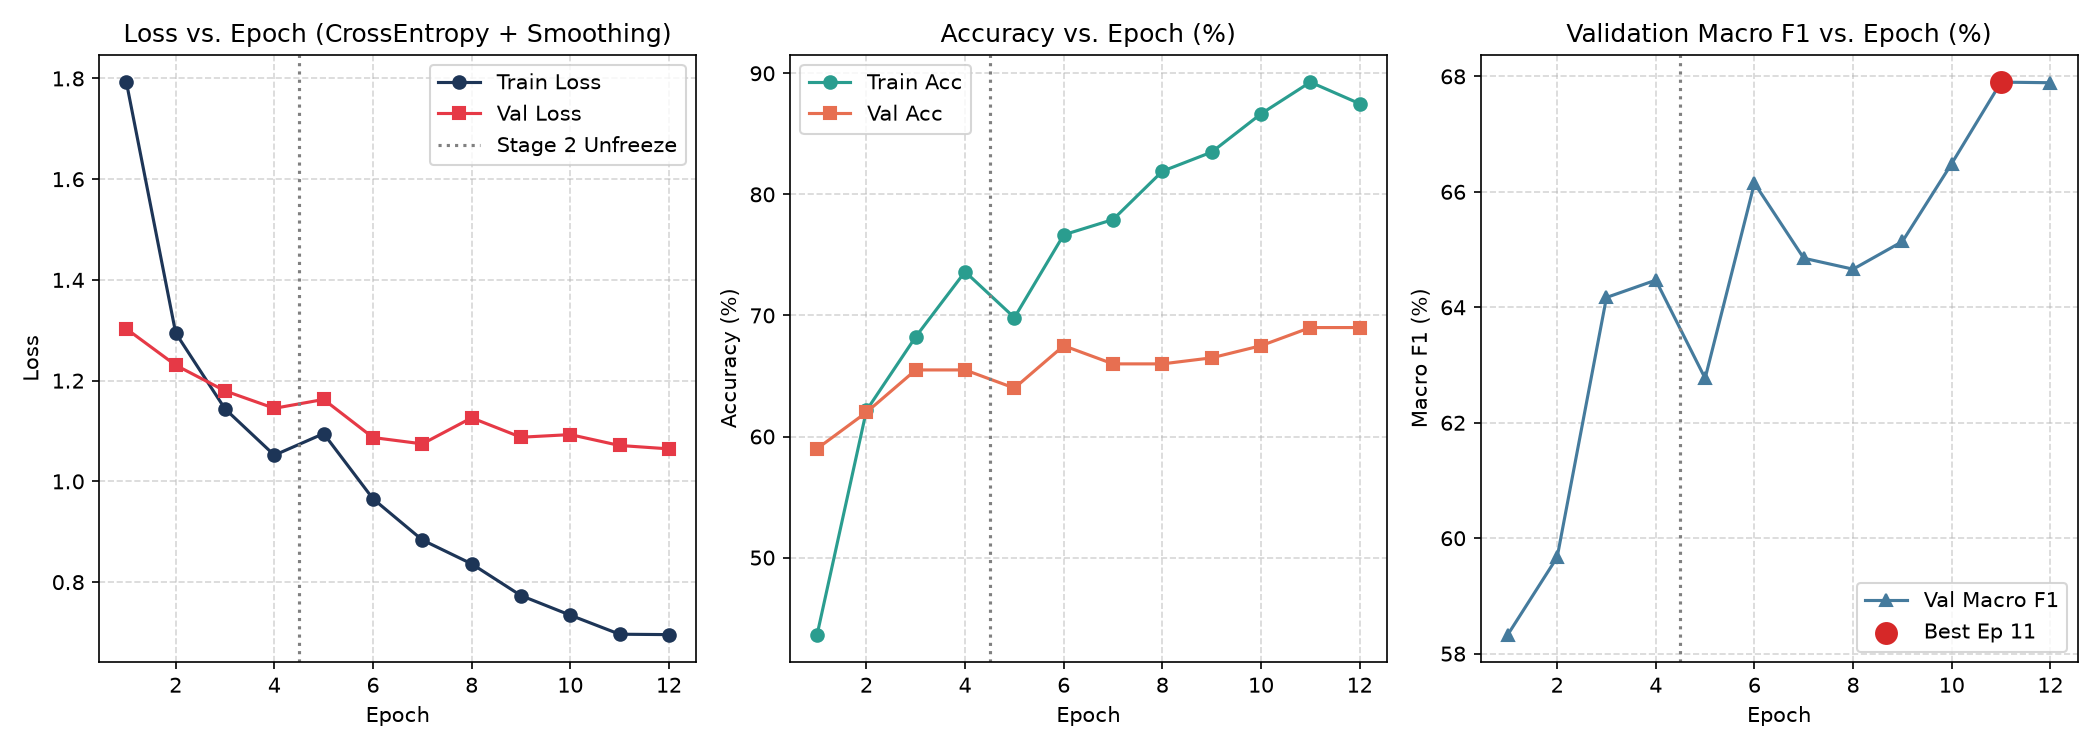

In [5]:
from IPython.display import Image, display

curves_path = PROJECT_ROOT / "reports" / "mobilenetv3_training_curves.png"
if curves_path.exists():
    display(Image(filename=str(curves_path)))
else:
    print("Curves plot not found.")


## 6. Validation-Based Checkpoint Selection
The candidate model checkpoint is selected strictly using validation data. The epoch that attained the highest Validation Macro F1 is selected to avoid overfitting on majority classes.


In [6]:
val_metrics_path = PROJECT_ROOT / "reports" / "mobilenetv3_validation_metrics.json"
if val_metrics_path.exists():
    with open(val_metrics_path, "r", encoding="utf-8") as f:
        val_m = json.load(f)
    print(f"Best Candidate Epoch:        {val_m.get('best_epoch')}")
    print(f"Best Validation Macro F1:    {val_m.get('best_val_macro_f1') * 100:.2f}%")
    print(f"Best Validation Loss:        {val_m.get('best_val_loss'):.4f}")
    print(f"Total Training Duration:     {val_m.get('total_training_time_seconds'):.1f}s")
    print(f"Candidate Checkpoint Path:   {val_m.get('checkpoint_path')}")


Best Candidate Epoch:        11
Best Validation Macro F1:    67.90%
Best Validation Loss:        1.0713
Total Training Duration:     436.4s
Candidate Checkpoint Path:   models\mobilenetv3_small_transfer.pth


## 7. Held-Out Test Evaluation (214 Untouched Images)
Now, we inspect the evaluation of the selected candidate on the 214 held-out test images.


In [7]:
test_metrics_path = PROJECT_ROOT / "reports" / "mobilenetv3_test_metrics.json"
if test_metrics_path.exists():
    with open(test_metrics_path, "r", encoding="utf-8") as f:
        test_m = json.load(f)

    print("=" * 65)
    print(f"Model:                 {test_m.get('model_name')}")
    print(f"Pretrained Weights:    {test_m.get('pretrained_weights')}")
    print(f"Test Accuracy:         {test_m.get('test_accuracy') * 100:.2f}%")
    print(f"Balanced Accuracy:     {test_m.get('balanced_accuracy') * 100:.2f}%")
    print(f"Macro Precision:       {test_m.get('macro_precision') * 100:.2f}%")
    print(f"Macro Recall:          {test_m.get('macro_recall') * 100:.2f}%")
    print(f"Macro F1-Score:        {test_m.get('macro_f1') * 100:.2f}%")
    print(f"Weighted F1-Score:     {test_m.get('weighted_f1') * 100:.2f}%")
    print(f"Average CPU Latency:   {test_m.get('average_latency_ms'):.2f} ms")
    print("=" * 65)

    print("\nPer-Class Performance Breakdown:")
    print(f"{'Class Name':30s} | {'Precision':10s} | {'Recall':10s} | {'F1-Score':10s} | {'Support':7s}")
    print("-" * 75)
    for cls, vals in test_m.get("per_class_metrics", {}).items():
        print(f"{cls:30s} | {vals['precision']*100:9.1f}% | {vals['recall']*100:9.1f}% | {vals['f1_score']*100:9.1f}% | {vals['support']:7d}")


Model:                 MobileNetV3-Small
Pretrained Weights:    ImageNet-1K
Test Accuracy:         67.29%
Balanced Accuracy:     65.98%
Macro Precision:       69.10%
Macro Recall:          65.98%
Macro F1-Score:        66.52%
Weighted F1-Score:     67.57%
Average CPU Latency:   11.09 ms

Per-Class Performance Breakdown:
Class Name                     | Precision  | Recall     | F1-Score   | Support
---------------------------------------------------------------------------
Blueberry leaf                 |      60.0% |      83.3% |      69.8% |      18
Corn leaf blight               |      83.3% |      86.2% |      84.8% |      29
Corn rust leaf                 |      77.8% |      77.8% |      77.8% |      18
Peach leaf                     |      93.3% |      77.8% |      84.9% |      18
Potato leaf early blight       |      40.0% |      44.4% |      42.1% |      18
Potato leaf late blight        |      50.0% |      56.2% |      52.9% |      16
Raspberry leaf                 |      91.7

## 8. Confusion Matrix Analysis
We examine the confusion matrix to understand misclassifications between visually similar pathologies (e.g., blight symptoms across crops).


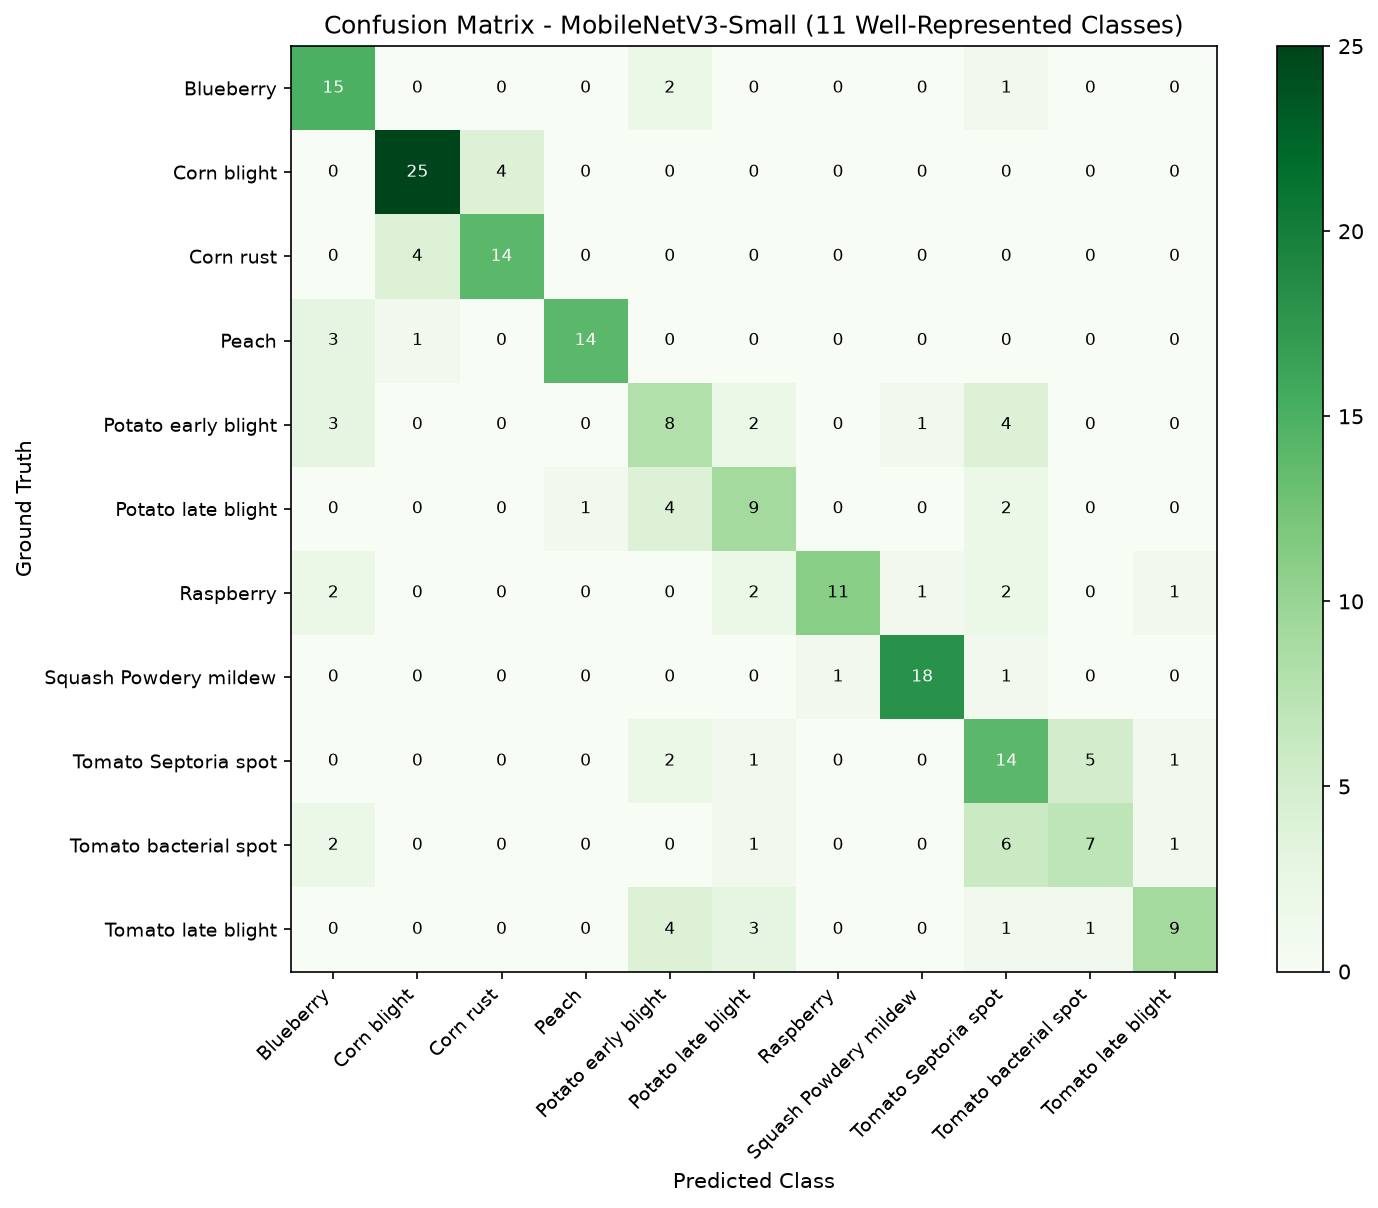

In [8]:
cm_img_path = PROJECT_ROOT / "reports" / "mobilenetv3_confusion_matrix.png"
if cm_img_path.exists():
    display(Image(filename=str(cm_img_path)))


## 9. Grad-CAM Visual Explanations
We verify whether MobileNetV3-Small attends to actual necrotic lesions, spots, and pustules on leaf tissue rather than background soil, stems, or photography artifacts.
Target convolutional layer: `model.features[-1]` (the final $1\times 1$ pointwise conv before global average pooling).


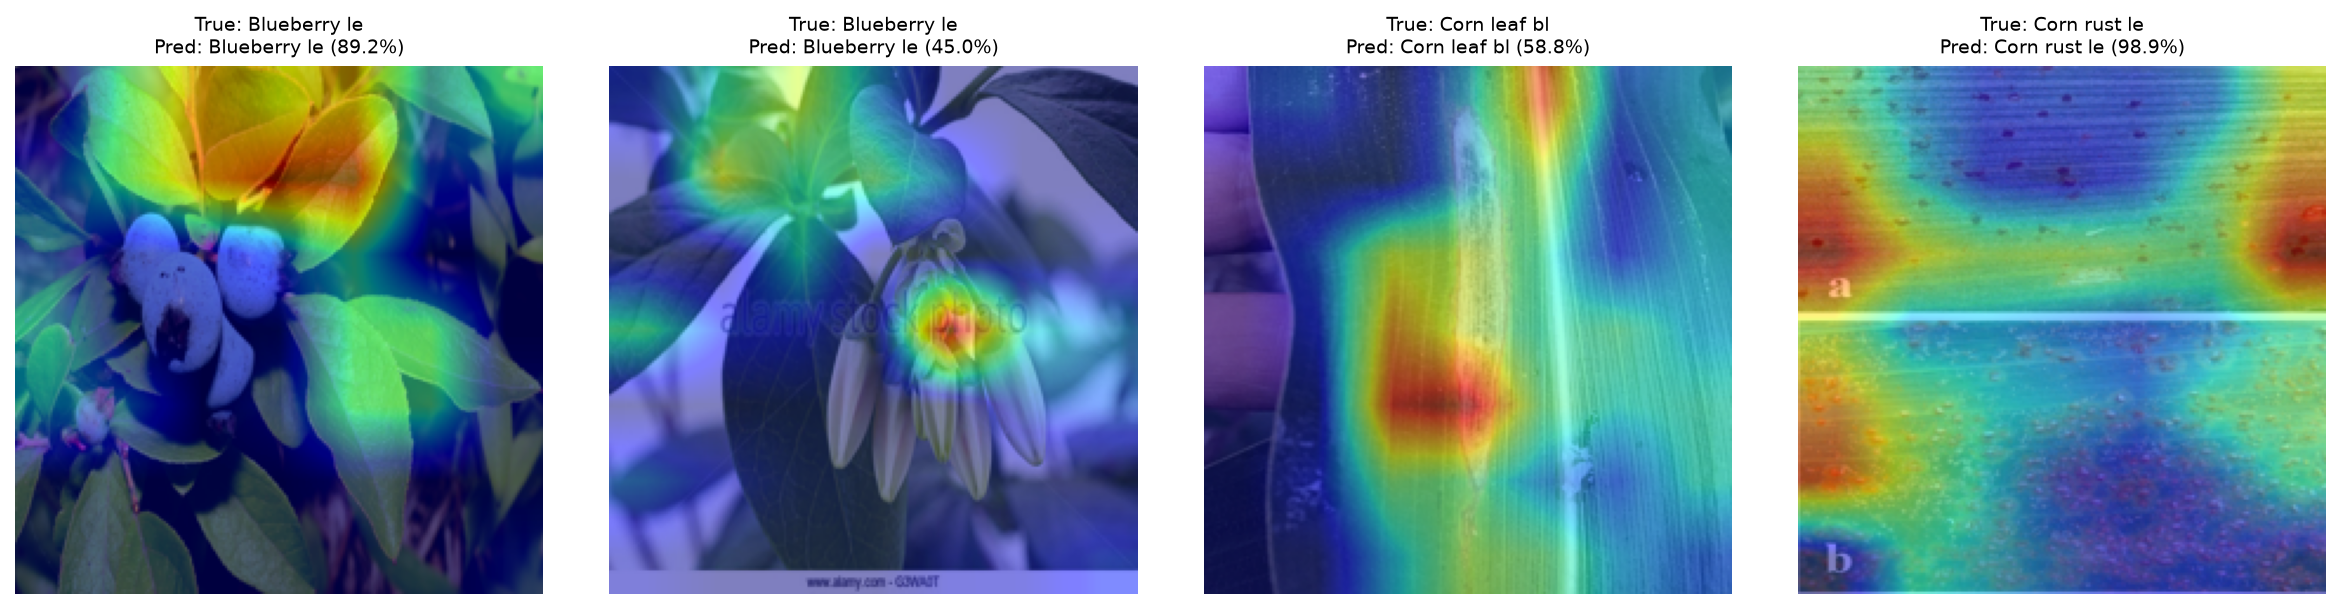

In [9]:
gradcam_sample_path = PROJECT_ROOT / "reports" / "mobilenetv3_sample_predictions.png"
if gradcam_sample_path.exists():
    display(Image(filename=str(gradcam_sample_path)))


## 10. Head-to-Head Comparison: Scratch Baseline vs. MobileNetV3-Small

We present a direct comparison on the identical 214 held-out test samples.


In [10]:
comparison_path = PROJECT_ROOT / "reports" / "mobilenetv3_comparison.json"
if comparison_path.exists():
    with open(comparison_path, "r", encoding="utf-8") as f:
        comp = json.load(f)

    b = comp["scratch_trained_baseline"]
    m = comp["transfer_learning_candidate"]
    d = comp["delta"]

    comp_table = [
        ("Model Architecture", b["architecture"], m["architecture"], "N/A"),
        ("Pretrained Weights", "None (Random Init)", "ImageNet-1K", "N/A"),
        ("Test Accuracy", f"{b['test_accuracy']*100:.2f}%", f"{m['test_accuracy']*100:.2f}%", f"{d['test_accuracy_diff']*100:+.2f}%"),
        ("Macro F1-Score", f"{b['macro_f1']*100:.2f}%", f"{m['macro_f1']*100:.2f}%", f"{d['macro_f1_diff']*100:+.2f}%"),
        ("Balanced Accuracy", f"{b['balanced_accuracy']*100:.2f}%", f"{m['balanced_accuracy']*100:.2f}%", f"{d['balanced_accuracy_diff']*100:+.2f}%"),
        ("Macro Precision", f"{b['macro_precision']*100:.2f}%", f"{m['macro_precision']*100:.2f}%", "N/A"),
        ("Macro Recall", f"{b['macro_recall']*100:.2f}%", f"{m['macro_recall']*100:.2f}%", "N/A"),
        ("Avg Latency (CPU)", f"{b['average_latency_ms']:.2f} ms", f"{m['average_latency_ms']:.2f} ms", f"{d['latency_diff_ms']:+.2f} ms"),
    ]

    print(f"{'Metric':22s} | {'Scratch Baseline':25s} | {'MobileNetV3 Transfer':25s} | {'Delta':10s}")
    print("-" * 88)
    for row in comp_table:
        print(f"{row[0]:22s} | {row[1]:25s} | {row[2]:25s} | {row[3]:10s}")


Metric                 | Scratch Baseline          | MobileNetV3 Transfer      | Delta     
----------------------------------------------------------------------------------------
Model Architecture     | Custom CNN (EnhancedCropCNN) | MobileNetV3-Small (ImageNet-1K pretrained) | N/A       
Pretrained Weights     | None (Random Init)        | ImageNet-1K               | N/A       
Test Accuracy          | 27.10%                    | 67.29%                    | +40.19%   
Macro F1-Score         | 21.74%                    | 66.52%                    | +44.78%   
Balanced Accuracy      | 27.10%                    | 65.98%                    | +38.88%   
Macro Precision        | 24.03%                    | 69.10%                    | N/A       
Macro Recall           | 27.10%                    | 65.98%                    | N/A       
Avg Latency (CPU)      | 14.05 ms                  | 11.09 ms                  | -2.96 ms  


## 11. Engineering Limitations & Agronomic Guidance Boundaries

1. **Visual Pattern Correlation vs. Biological Cause:**  
   The model recognizes superficial visual discoloration patterns (spots, chlorosis, necrosis) across field imagery. It cannot infer sub-surface vascular pathogens, fungal mycelium penetration, or soil nutritional deficits without laboratory assay.
2. **Ambiguous Symptom Confounding:**  
   Field images often contain co-occurring stressors (e.g., insect chewing co-occurring with blight), leading to lower confidence. The application enforces a heuristic low-score threshold ($\le 60\%$) to flag uncertain predictions.
3. **No Chemical Prescription:**  
   Consistent with GenHack PS 12 requirements, FarmWatch AI never provides automated chemical dosages or unsupervised fungicide application instructions. All outputs are strictly scoped to non-chemical cultural sanitation and referral to certified agronomists.
